<a href="https://colab.research.google.com/github/ShenlyR/Tim-Sukses_Gelar-Rasa-2026/blob/main/Tim_Sukses_Gelar_Rasa_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Library

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os
import re

Merge dataset

In [ ]:
# Merge dataset
input_loc = "/content/drive/MyDrive/Dataset Gelar/"
output_loc = "/content/drive/MyDrive/Dataset merge/"

In [ ]:
filelist = os.listdir(input_loc)
filelist

['hospitals.csv',
 'BGR-02_Baranangsiang_AQMS.csv',
 'BGR-01_Cisarua_AQMS.csv',
 'MDN-01_Medan_AQMS.csv',
 'BTM-01_Batam_AQMS.csv',
 'JKT-03_Cengkareng_AQMS.csv',
 'KTG-02_Sampit_AQMS.csv',
 'SRG-01_Sorong_AQMS.csv',
 'KTG-01_PalangkaRaya_AQMS.csv',
 'sites.csv',
 'PKU-01_Pekanbaru_AQMS.csv',
 'MRS-01_Maros_AQMS.csv',
 'PKN-01_PangkalanBun_AQMS.csv',
 'PLB-01_TalangBetutu_AQMS.csv',
 'STG-01_Sintang_AQMS.csv',
 'sensors.csv',
 'KTB-01_Kototabang_AQMS.csv',
 'JMB-02_MuaroJambi_AQMS.csv',
 'MER-01_Merauke_AQMS.csv',
 'SM2-01_Samarinda_AQMS.csv',
 'YKY-01_Sleman_AQMS.csv',
 'BGL-01_Bengkulu_AQMS.csv',
 'BJB-01_Banjarbaru_AQMS.csv',
 'JMB-01_KotaJambi_AQMS.csv',
 'IDP-01_Indrapuri_AQMS.csv',
 'PSW-01_Pesawaran_AQMS.csv',
 'JKT-01_Gambir_AQMS.csv',
 'HLT-01_health_outcomes_daily.csv',
 'MLG-01_Malang_AQMS.csv',
 'JKT-02_Marunda_AQMS.csv',
 'PLU-01_LoreLindu_AQMS.csv',
 'metadata']

In [ ]:
# memeriksa jumlah baris dan kolomm metadata
meta_sensors = pd.read_csv(input_loc + 'metadata/metadata_sensors.csv')
meta_dates = pd.read_csv(input_loc + 'metadata/metadata_dates.csv')
print('Metadata sensors:', meta_sensors.shape)
print('Metadata dates:', meta_dates.shape)

Metadata sensors: (16, 6)
Metadata dates: (27, 6)


In [ ]:
# membaca data master
sensors_df = pd.read_csv(input_loc + 'sensors.csv')
sites_df = pd.read_csv(input_loc + 'sites.csv')
hospitals_df = pd.read_csv(input_loc + 'hospitals.csv')
health_df = pd.read_csv(input_loc + 'HLT-01_health_outcomes_daily.csv')

In [ ]:
# menggabungkan data sensor dan lokasi
sensor_location = sensors_df.merge(
    sites_df[['location_id', 'provinsi', 'kota_kabupaten', 'kecamatan']],
    on='location_id',
    how='left'
)

# hasil penggabungan sensor dan lokasi
print('Hasil penggabungan sensor dan lokasi')
display(
    sensor_location[
        ['sensor_id', 'location_id', 'kecamatan', 'kota_kabupaten']
    ].head()
)

# memetakan sensor ke rumah sakit berdasarkan wilayah
master_mapping = sensor_location.merge(
    hospitals_df[
        ['hospital_id', 'nama_rumah_sakit', 'kecamatan',
         'kota_kabupaten', 'provinsi']
    ],
    on=['kecamatan', 'kota_kabupaten', 'provinsi'],
    how='inner',
    suffixes=('_sensor', '_hospital')
)

# hasil mapping sensor dan rumah sakit
print('\nMaster mapping sensor dan rumah sakit')
display(
    master_mapping[
        ['sensor_id', 'location_id', 'kecamatan', 'kota_kabupaten',
         'hospital_id', 'nama_rumah_sakit']
    ].head(10)
)

# menghitung jumlah sensor
print(
    '\nJumlah sensor unik yang berhasil mapping:',
    master_mapping['sensor_id'].nunique()
)
print('Jumlah total sensor:', sensors_df['sensor_id'].nunique())

# mengidentifikasi sensor yang belum memiliki pasangan rumah sakit
sensor_with_rs = set(master_mapping['sensor_id'].unique())
all_sensors = set(sensors_df['sensor_id'].unique())
sensors_without_rs = all_sensors - sensor_with_rs

if sensors_without_rs:
    print('Sensor yang belum memiliki pasangan rumah sakit:')
    display(
        sensor_location[
            sensor_location['sensor_id'].isin(sensors_without_rs)
        ][['sensor_id', 'kecamatan', 'kota_kabupaten']]
    )

Hasil penggabungan sensor dan lokasi


,sensor_id,location_id,kecamatan,kota_kabupaten
0,SENS-001,LOC-JKT-01,Gambir,Kota Administrasi Jakarta Pusat
1,SENS-002,LOC-JKT-02,Cilincing (Marunda),Kota Administrasi Jakarta Utara
2,SENS-003,LOC-JKT-03,Cengkareng,Kota Administrasi Jakarta Barat
3,SENS-004,LOC-KTG-01,Jekan Raya,Kota Palangka Raya
4,SENS-005,LOC-KTG-02,Mentawa Baru Ketapang (Sampit),Kabupaten Kotawaringin Timur



Master mapping sensor dan rumah sakit


,sensor_id,location_id,kecamatan,kota_kabupaten,hospital_id,nama_rumah_sakit
0,SENS-004,LOC-KTG-01,Jekan Raya,Kota Palangka Raya,RS-XXX-04,RSUD XXX Jekan Raya
1,SENS-006,LOC-BGR-01,Cisarua,Kabupaten Bogor,RS-XXX-06,RS Paru XXX Cisarua
2,SENS-008,LOC-YKY-01,Mlati,Kabupaten Sleman,RS-XXX-08,RSUD XXX Sleman
3,SENS-009,LOC-IDP-01,Indrapuri,Kabupaten Aceh Besar,RS-XXX-09,RSUD XXX Indrapuri
4,SENS-010,LOC-KTB-01,Palembayan,Kabupaten Agam,RS-XXX-10,RSUD XXX Agam
5,SENS-011,LOC-PKU-01,Marpoyan Damai,Kota Pekanbaru,RS-XXX-11,RSUD XXX Pekanbaru
6,SENS-012,LOC-JMB-01,Jambi Selatan,Kota Jambi,RS-XXX-12,RSUD XXX Kota Jambi
7,SENS-013,LOC-BTM-01,Batu Besar,Kota Batam,RS-XXX-13,RSUD XXX Batam
8,SENS-014,LOC-BGL-01,Selebar,Kota Bengkulu,RS-XXX-14,RSUD XXX Bengkulu
9,SENS-015,LOC-SRG-01,Sorong Timur,Kota Sorong,RS-XXX-15,RSUD XXX Sorong



Jumlah sensor unik yang berhasil mapping: 20
Jumlah total sensor: 27
Sensor yang belum memiliki pasangan rumah sakit:


,sensor_id,kecamatan,kota_kabupaten
0,SENS-001,Gambir,Kota Administrasi Jakarta Pusat
1,SENS-002,Cilincing (Marunda),Kota Administrasi Jakarta Utara
2,SENS-003,Cengkareng,Kota Administrasi Jakarta Barat
4,SENS-005,Mentawa Baru Ketapang (Sampit),Kabupaten Kotawaringin Timur
6,SENS-007,Bogor Tengah (Baranangsiang),Kota Bogor
20,SENS-021,Sukarami (Talang Betutu),Kota Palembang
21,SENS-022,Tegineneng (Masgar),Kabupaten Pesawaran


In [ ]:
# Fungsi normalisasi nama kota/kabupaten
def normalize_kota(name):
    if pd.isna(name):
        return name

    s = str(name).strip().lower()
    s = re.sub(
        r'^(kota\s+administrasi|kabupaten\s+administrasi|kota|kabupaten)\s+',
        '',
        s
    )
    s = re.sub(r'\s+', ' ', s).strip()

    return s

# Fungsi normalisasi nama kecamatan
def normalize_kecamatan(name):
    if pd.isna(name):
        return name

    s = str(name).strip().lower()
    s = re.sub(r'\s*\(.*?\)\s*', '', s)
    s = re.sub(r'\s+', ' ', s).strip()

    return s

# informasi lokasi sensor
sites_norm = sites_df[
    ['location_id', 'provinsi', 'kota_kabupaten', 'kecamatan']
].copy()

sites_norm['kota_norm'] = sites_norm['kota_kabupaten'].apply(normalize_kota)
sites_norm['kecamatan_norm'] = sites_norm['kecamatan'].apply(normalize_kecamatan)

# Menggabungkan data sensor dan informasi lokasi
sensor_side = sensors_df.merge(
    sites_norm,
    on='location_id',
    how='left'
).rename(columns={
    'provinsi': 'provinsi_sensor',
    'kota_kabupaten': 'kota_kabupaten_sensor',
    'kecamatan': 'kecamatan_sensor'
})

# informasi lokasi rumah sakit
hosp_norm = hospitals_df.copy()

hosp_norm['kota_norm'] = hosp_norm['kota_kabupaten'].apply(normalize_kota)
hosp_norm['kecamatan_norm'] = hosp_norm['kecamatan'].apply(normalize_kecamatan)

hospital_side = hosp_norm.rename(columns={
    'provinsi': 'provinsi_hospital',
    'kota_kabupaten': 'kota_kabupaten_hospital',
    'kecamatan': 'kecamatan_hospital'
})

In [ ]:
# Menggabungkan data sensor dan rumah sakit berdasarkan wilayah
master_mapping = sensor_side.merge(
    hospital_side[
        [
            'hospital_id',
            'nama_rumah_sakit',
            'provinsi_hospital',
            'kota_kabupaten_hospital',
            'kecamatan_hospital',
            'kota_norm',
            'kecamatan_norm'
        ]
    ],
    left_on=['kota_norm', 'kecamatan_norm', 'provinsi_sensor'],
    right_on=['kota_norm', 'kecamatan_norm', 'provinsi_hospital'],
    how='left'
)

# Memisahkan sensor yang berhasil dan belum berhasil dipasangkan
matched = master_mapping[master_mapping['hospital_id'].notna()]
unmatched = master_mapping[master_mapping['hospital_id'].isna()]

# Menampilkan hasil pencocokan
print(
    f"Sensor dengan pasangan RS: "
    f"{matched['sensor_id'].nunique()} / {sensors_df['sensor_id'].nunique()}"
)
print(f"Sensor tanpa pasangan RS: {unmatched['sensor_id'].nunique()}")

if not unmatched.empty:
    print("\nSensor yang belum memiliki pasangan RS:")
    display(
        unmatched[
            ['sensor_id', 'kecamatan_sensor', 'kota_kabupaten_sensor']
        ].drop_duplicates()
    )

# Memilih kolom yang diperlukan dan menghapus pasangan duplikat
master_mapping_clean = matched[
    [
        'sensor_id',
        'location_id',
        'hospital_id',
        'nama_rumah_sakit',
        'provinsi_sensor',
        'kota_kabupaten_sensor',
        'kecamatan_sensor'
    ]
].rename(columns={
    'provinsi_sensor': 'provinsi',
    'kota_kabupaten_sensor': 'kota_kabupaten',
    'kecamatan_sensor': 'kecamatan'
}).drop_duplicates(subset=['sensor_id', 'hospital_id'])

# Menyimpan hasil mapping
master_mapping_clean.to_csv(
    output_loc + 'master_mapping.csv',
    index=False
)

print(f"\nFile tersimpan: {output_loc}master_mapping.csv")
print(f"Total pasangan sensor-RS: {len(master_mapping_clean)}")

Sensor dengan pasangan RS: 27 / 27
Sensor tanpa pasangan RS: 0

File tersimpan: /content/drive/MyDrive/Dataset merge/master_mapping.csv
Total pasangan sensor-RS: 27


In [ ]:
input_loc = "/content/drive/MyDrive/Dataset Gelar/"
output_loc = "/content/drive/MyDrive/Dataset merge/"

# Mengidentifikasi seluruh file AQMS
filelist = os.listdir(input_loc)
aqms_files = [
    f for f in filelist
    if f.endswith('.csv') and 'AQMS' in f
]

# Membaca dan menggabungkan data AQMS
merge_list = []

for f in aqms_files:
    df = pd.read_csv(input_loc + f, low_memory=False)
    merge_list.append(df)

    print(
        f"{f:50s} | "
        f"{df.shape[0]:>7,} baris | "
        f"{df.shape[1]:>2} kolom"
    )

# Menggabungkan seluruh data
merge_df = pd.concat(merge_list, ignore_index=True)

# Menampilkan ringkasan hasil penggabungan
print(f"\nTotal file AQMS    : {len(merge_list)}")
print(f"Total baris gabung : {len(merge_df):,}")
print(f"Total kolom        : {merge_df.shape[1]}")

print("\nKolom dataset:")
print(merge_df.columns.tolist())

# Menyimpan hasil penggabungan
merge_df.to_csv(output_loc + 'merge_result.csv', index=False)

print(f"\nFile tersimpan: {output_loc}merge_result.csv")

BGR-02_Baranangsiang_AQMS.csv                      |  24,432 baris | 15 kolom
BGR-01_Cisarua_AQMS.csv                            |  24,432 baris | 15 kolom
MDN-01_Medan_AQMS.csv                              |  20,800 baris | 15 kolom
BTM-01_Batam_AQMS.csv                              |  24,432 baris | 15 kolom
JKT-03_Cengkareng_AQMS.csv                         |  24,432 baris | 15 kolom
KTG-02_Sampit_AQMS.csv                             |  24,432 baris | 15 kolom
SRG-01_Sorong_AQMS.csv                             |  24,432 baris | 15 kolom
KTG-01_PalangkaRaya_AQMS.csv                       |  24,432 baris | 15 kolom
PKU-01_Pekanbaru_AQMS.csv                          |  24,432 baris | 15 kolom
MRS-01_Maros_AQMS.csv                              |  24,432 baris | 15 kolom
PKN-01_PangkalanBun_AQMS.csv                       |  24,432 baris | 15 kolom
PLB-01_TalangBetutu_AQMS.csv                       |  36,381 baris | 15 kolom
STG-01_Sintang_AQMS.csv                            |  24,432 bar

In [ ]:
# Membaca hasil penggabungan dan metadata sensor
finaldf = pd.read_csv(output_loc + 'merge_result.csv', low_memory=False)
meta_sensors = pd.read_csv(input_loc + 'metadata/metadata_sensors.csv')

# ekstrak nama kolom ppm berdasarkan metadata
def parse_ppm_columns(meta_df):
    ppm_cols = set()

    for _, row in meta_df.iterrows():
        header = str(row.get('Header', ''))
        units = str(row.get('Units', '')).lower()

        if 'ppm' not in units:
            continue

        parts = re.split(r'\s+or\s+|,\s*', header)

        for p in parts:
            p = p.strip()

            if p.endswith('_ppm'):
                ppm_cols.add(p)

    return sorted(ppm_cols)


ppm_cols_meta = parse_ppm_columns(meta_sensors)
print(f"Kolom ppm dari metadata: {ppm_cols_meta}")

# cek tipe data numerik
column_ug = [
    'pm25_ug_m3', 'pm10_ug_m3',
    'so2_ug_m3', 'co_ug_m3',
    'o3_ug_m3', 'no2_ug_m3'
]

for col in column_ug:
    if col not in finaldf.columns:
        finaldf[col] = np.nan

    finaldf[col] = pd.to_numeric(finaldf[col], errors='coerce')

# Konversi konsentrasi gas dari ppm ke µg/m³
gas_bm = {
    'so2': 64.07,
    'no2': 46.01,
    'o3': 48.00,
    'co': 28.01
}

molar_vol = 24.45
konversi = []
konversi_log = {}

for g in ['so2', 'co', 'o3', 'no2']:
    ppm_col = f'{g}_ppm'
    ug_col = f'{g}_ug_m3'

    if ppm_col not in finaldf.columns:
        continue

    if ppm_col not in ppm_cols_meta:
        print(f"{ppm_col} dikonversi tetapi tidak terdaftar dalam metadata")

    ppm_vals = pd.to_numeric(finaldf[ppm_col], errors='coerce')
    mask = ppm_vals.notna()

    overlap = mask & finaldf[ug_col].notna()

    if overlap.any():
        print(
            f"{ppm_col}: {overlap.sum():,} baris terisi "
            f"di kedua kolom. Nilai ppm diabaikan."
        )

    n_konv = (mask & ~overlap).sum()

    if n_konv > 0:
        factor = gas_bm[g] * 1000 / molar_vol

        finaldf.loc[mask & ~overlap, ug_col] = (
            ppm_vals[mask & ~overlap] * factor
        )

        konversi_log[ppm_col] = n_konv
        konversi.append(ppm_col)


# Konversi partikulat dari mg/m³ ke µg/m³
pm_factor = 1000.0

for g in ['pm25', 'pm10']:
    ppm_col = f'{g}_ppm'
    ug_col = f'{g}_ug_m3'

    if ppm_col not in finaldf.columns:
        continue

    if ppm_col not in ppm_cols_meta:
        print(f"{ppm_col} dikonversi tapi tidak ada di metadata")

    ppm_vals = pd.to_numeric(finaldf[ppm_col], errors='coerce')
    mask = ppm_vals.notna()

    overlap = mask & finaldf[ug_col].notna()

    if overlap.any():
        print(
            f"{ppm_col}: {overlap.sum():,} baris terisi "
        )

    n_konv = (mask & ~overlap).sum()

    if n_konv > 0:
        finaldf.loc[mask & ~overlap, ug_col] = (
            ppm_vals[mask & ~overlap] * pm_factor
        )

        konversi_log[ppm_col] = n_konv
        konversi.append(ppm_col)


# tanda sumber satuan
finaldf['unit_source'] = 'ug_m3'

for col in konversi:
    mask_konv = finaldf[col].notna()
    finaldf.loc[mask_konv, 'unit_source'] = 'ppm_converted'


# menghapus kolom yang sudah dikonversi
finaldf = finaldf.drop(columns=konversi, errors='ignore')


# cek tipe data sesuai
numeric_column = column_ug + [
    'temperature_c',
    'humidity_pct',
    'wind_speed_ms',
    'wind_direction_deg'
]

for col in numeric_column:
    if col in finaldf.columns:
        finaldf[col] = pd.to_numeric(finaldf[col], errors='coerce')


# urutan kolom
column_order = [
    'measurement_id', 'sensor_id',
    'timestamp_start', 'timestamp_end',
    'pm25_ug_m3', 'pm10_ug_m3',
    'so2_ug_m3', 'co_ug_m3', 'o3_ug_m3', 'no2_ug_m3',
    'temperature_c', 'humidity_pct',
    'wind_speed_ms', 'wind_direction_deg',
    'qc_flag', 'unit_source'
]

remaining = [c for c in finaldf.columns if c not in column_order]
finaldf = finaldf[column_order + remaining]


# Menampilkan ringkasan hasil konversi
print("\nHasil")

if konversi_log:
    for col, n in konversi_log.items():
        print(f"{col:15s} : {n:>7,} baris dikonversi")
else:
    print("Tidak ada kolom ppm yang terisi.")

print("\nDistribusi unit_source:")
print(finaldf['unit_source'].value_counts().to_string())


# cek konsistensi hasil konversi dan metadata
ppm_meta_set = set(ppm_cols_meta)
konversi_set = set(konversi)

tidak_dikonv = ppm_meta_set - konversi_set
tidak_di_meta = konversi_set - ppm_meta_set

if tidak_dikonv:
    print(
        "\nKolom ppm di metadata tetapi tidak dikonversi "
        f"(kemungkinan kosong): {tidak_dikonv}"
    )

if tidak_di_meta:
    print(
        "\nKolom dikonversi tetapi tidak terdaftar dalam metadata: "
        f"{tidak_di_meta}"
    )

if not tidak_dikonv and not tidak_di_meta:
    print("\nSemua kolom konversi konsisten dengan metadata.")


# Menyimpan hasil cleaning
finaldf.to_csv(
    output_loc + 'cleaning_dataset.csv',
    index=False
)

print(f"\nFile tersimpan: {output_loc}cleaning_dataset.csv")
print(f"Total baris: {len(finaldf):,}")
print(f"Total kolom: {finaldf.shape[1]}")

Kolom ppm dari metadata: ['co_ppm', 'no2_ppm', 'o3_ppm', 'pm10_ppm', 'pm25_ppm', 'so2_ppm']

Hasil
so2_ppm         :  69,040 baris dikonversi
co_ppm          :  69,040 baris dikonversi
o3_ppm          :  69,040 baris dikonversi
no2_ppm         :  69,040 baris dikonversi
pm25_ppm        :  69,040 baris dikonversi
pm10_ppm        :  69,040 baris dikonversi

Distribusi unit_source:
unit_source
ug_m3            598941
ppm_converted     69040

Semua kolom konversi konsisten dengan metadata.

File tersimpan: /content/drive/MyDrive/Dataset merge/cleaning_dataset.csv
Total baris: 667,981
Total kolom: 16


**Data Preprocessing**

In [ ]:
# Membaca hasil cleaning
df_clean = pd.read_csv(output_loc + 'cleaning_dataset.csv', low_memory=False)

# Memeriksa kolom penting
required_cols = [
    'measurement_id', 'sensor_id',
    'timestamp_start', 'timestamp_end', 'qc_flag'
]

missing_required = [col for col in required_cols if col not in df_clean.columns]

if missing_required:
    raise ValueError(f"Kolom wajib tidak ditemukan: {missing_required}")

# Memfilter data dengan status VALID
df_valid = df_clean[df_clean['qc_flag'] == 'VALID'].copy()

# Konversi kolom waktu ke datetime
df_valid['timestamp_start'] = pd.to_datetime(
    df_valid['timestamp_start'], format='mixed', errors='coerce'
)

df_valid['timestamp_end'] = pd.to_datetime(
    df_valid['timestamp_end'], format='mixed', errors='coerce'
)

# Menghitung missing timestamp
n_missing_start = df_valid['timestamp_start'].isna().sum()
n_missing_end = df_valid['timestamp_end'].isna().sum()

# tabel audit
audit_data = pd.DataFrame({
    'Keterangan': [
        'Total baris sebelum filter',
        'Total baris setelah filter VALID',
        'Duplikat measurement_id',
        'Missing timestamp_start',
        'Missing timestamp_end'
    ],
    'Jumlah': [
        len(df_clean),
        len(df_valid),
        df_valid['measurement_id'].duplicated().sum(),
        n_missing_start,
        n_missing_end
    ]
})

display(audit_data)

# sampel timestamp yang gagal dikonversi
if n_missing_start > 0 or n_missing_end > 0:
    fail_sample = df_valid[
        df_valid['timestamp_start'].isna() |
        df_valid['timestamp_end'].isna()
    ]

    display(
        fail_sample[
            ['measurement_id', 'sensor_id', 'timestamp_start', 'timestamp_end']
        ].head(5)
    )

# Menghapus baris tanpa timestamp_start
df_valid = df_valid.dropna(subset=['timestamp_start']).copy()

print(f"Total baris setelah menghapus timestamp_start kosong: {len(df_valid):,}")

,Keterangan,Jumlah
0,Total baris sebelum filter,667981
1,Total baris setelah filter VALID,599185
2,Duplikat measurement_id,0
3,Missing timestamp_start,0
4,Missing timestamp_end,0


Total baris setelah menghapus timestamp_start kosong: 599,185


In [ ]:
# kolom qc_flag
sebaran_qc = df_clean['qc_flag'].value_counts(dropna=False).reset_index()
sebaran_qc.columns = ['qc_flag', 'Jumlah']

display(sebaran_qc)

,qc_flag,Jumlah
0,VALID,599185
1,SUSPECT,19741
2,MISSING,13675
3,CALIBRATING,8072
4,WARMUP,3764
5,PARSER_FAIL,3633
6,FATAL_ERR,3546
7,GARBAGE,3537
8,COMM_LOST,3433
9,CORRUPT,3425


In [ ]:
# memilih data dengan status VALID
df_valid = df_clean[df_clean['qc_flag'] == 'VALID'].copy()

print(f"Total data awal: {len(df_clean):,} baris")
print(f"Total data VALID: {len(df_valid):,} baris")


# menentukan kolom polutan
pollutant_column = [
    'pm25_ug_m3', 'pm10_ug_m3',
    'so2_ug_m3', 'co_ug_m3',
    'o3_ug_m3', 'no2_ug_m3'
]


# mengubah nilai negatif jadi NaN
print("\nNilai negatif yang ditemukan:")

check_column = pollutant_column + [
    'temperature_c', 'humidity_pct',
    'wind_speed_ms', 'wind_direction_deg'
]

for col in check_column:
    n_neg = (df_valid[col] < 0).sum()

    if n_neg > 0:
        print(f"{col:22s}: {n_neg:>6,} baris")
        df_valid.loc[df_valid[col] < 0, col] = np.nan


# menangani anomali PM2.5 yang lebih besar dari PM10
anomali_pm = df_valid['pm25_ug_m3'] > df_valid['pm10_ug_m3']

df_valid.loc[
    anomali_pm,
    ['pm25_ug_m3', 'pm10_ug_m3']
] = np.nan

print(f"\nAnomali PM2.5 > PM10: {anomali_pm.sum():,} baris")

# memeriksa rentang kelembapan
mask_rh = (
    (df_valid['humidity_pct'] < 0) |
    (df_valid['humidity_pct'] > 100)
)

df_valid.loc[mask_rh, 'humidity_pct'] = np.nan

print(f"Kelembapan di luar rentang 0-100: {mask_rh.sum():,} baris")

# memeriksa rentang arah angin
mask_wd = (
    (df_valid['wind_direction_deg'] < 0) |
    (df_valid['wind_direction_deg'] > 360)
)

df_valid.loc[mask_wd, 'wind_direction_deg'] = np.nan

print(f"Arah angin di luar rentang 0-360: {mask_wd.sum():,} baris")

# menghapus arah angin saat kecepatan angin bernilai nol
mask_wd_diam = (
    (df_valid['wind_speed_ms'] == 0) &
    (df_valid['wind_direction_deg'].notna())
)

df_valid.loc[mask_wd_diam, 'wind_direction_deg'] = np.nan

print(f"Arah angin saat kecepatan angin = 0: {mask_wd_diam.sum():,} baris")

# menangani anomali PM10 pada sensor SENS-027
mask_sens27 = (
    (df_valid['sensor_id'] == 'SENS-027') &
    (df_valid['pm10_ug_m3'] > 0) &
    (df_valid['pm10_ug_m3'] < 0.01)
)

df_valid.loc[mask_sens27, 'pm10_ug_m3'] = np.nan

print(f"Anomali PM10 SENS-027: {mask_sens27.sum():,} baris")

# cek nilai ekstrem
df_valid['is_extreme_pm25'] = df_valid['pm25_ug_m3'] > 250
df_valid['is_extreme_pm10'] = df_valid['pm10_ug_m3'] > 500

print(f'\nPM2.5 > 250 (Berbahaya): {df_valid["is_extreme_pm25"].sum():,} baris')
print(f'PM10 > 500            : {df_valid["is_extreme_pm10"].sum():,} baris')

Total data awal: 667,981 baris
Total data VALID: 599,185 baris

Nilai negatif yang ditemukan:

Anomali PM2.5 > PM10: 0 baris
Kelembapan di luar rentang 0-100: 0 baris
Arah angin di luar rentang 0-360: 0 baris
Arah angin saat kecepatan angin = 0: 0 baris
Anomali PM10 SENS-027: 0 baris

PM2.5 > 250 (Berbahaya): 8,391 baris
PM10 > 500            : 2,549 baris


In [ ]:
# konversi ke tipe datetime
df_valid['timestamp_start'] = pd.to_datetime(
    df_valid['timestamp_start'],
    format='mixed',
    errors='coerce'
)

# hasil
print(df_valid['timestamp_start'].dtype)

datetime64[ns]


In [ ]:
# Mengganti nilai tak hingga jadi NaN
df_valid = df_valid.replace([np.inf, -np.inf], np.nan)

# Membuat fitur waktu
df_valid['date'] = df_valid['timestamp_start'].dt.date
df_valid['hour'] = df_valid['timestamp_start'].dt.hour
df_valid['day_of_week'] = df_valid['timestamp_start'].dt.day_name()
df_valid['is_weekend'] = df_valid['timestamp_start'].dt.dayofweek >= 5
df_valid['month'] = df_valid['timestamp_start'].dt.month

# Menghitung rata-rata harian berdasarkan sensor
daily_aq = df_valid.groupby(['sensor_id', 'date']).agg(
    pm25_mean=('pm25_ug_m3', 'mean'),
    pm25_max=('pm25_ug_m3', 'max'),
    pm10_mean=('pm10_ug_m3', 'mean'),
    o3_mean=('o3_ug_m3', 'mean'),
    no2_mean=('no2_ug_m3', 'mean'),
    so2_mean=('so2_ug_m3', 'mean'),
    co_mean=('co_ug_m3', 'mean'),
    temp_mean=('temperature_c', 'mean'),
    rh_mean=('humidity_pct', 'mean'),
    ws_mean=('wind_speed_ms', 'mean'),
    n_valid_hours=('pm25_ug_m3', 'count')
).reset_index()

# Menentukan kelayakan data harian
daily_aq['is_representative'] = daily_aq['n_valid_hours'] >= 18

# indikator pelampauan baku PM2.5
bm_pm25 = 55
daily_aq['pm25_exceed'] = daily_aq['pm25_mean'] > bm_pm25

# Fungsi perhitungan indeks ISPU
def ispu_index(pm25):
    if pd.isna(pm25):
        return np.nan

    breakpoints = [
        (0.0, 15.5, 1, 50),
        (15.6, 55.4, 51, 100),
        (55.5, 150.4, 101, 200),
        (150.5, 250.4, 201, 300),
        (250.5, 500.0, 301, 500)
    ]

    for pm_lo, pm_hi, ispu_lo, ispu_hi in breakpoints:
        if pm25 <= pm_hi:
            return round(
                (ispu_hi - ispu_lo) / (pm_hi - pm_lo)
                * (pm25 - pm_lo) + ispu_lo
            )

    return 500

# kategori ISPU
def ispu_category(ispu_idx):
    if pd.isna(ispu_idx):
        return 'Tanpa Data'
    elif ispu_idx <= 50:
        return 'Baik'
    elif ispu_idx <= 100:
        return 'Sedang'
    elif ispu_idx <= 200:
        return 'Tidak Sehat'
    elif ispu_idx <= 300:
        return 'Sangat Tidak Sehat'
    else:
        return 'Berbahaya'

# Menghitung indeks dan kategori ISPU
daily_aq['ispu_index'] = daily_aq['pm25_mean'].apply(ispu_index)
daily_aq['kategori_ispu'] = daily_aq['ispu_index'].apply(ispu_category)


# hasil agregasi
print(f"Total hari pengamatan: {len(daily_aq):,}")
print(f"Hari sesuai kriteria: {daily_aq['is_representative'].sum():,}")


# distribusi kategori ISPU yang sesuai kriteria
sebaran_ispu = (
    daily_aq.loc[daily_aq['is_representative'], 'kategori_ispu']
    .value_counts()
    .reset_index()
)

sebaran_ispu.columns = ['Kategori ISPU', 'Jumlah']

display(sebaran_ispu)

# hasil
df_valid.to_csv(output_loc + 'hourly_valid.csv', index=False)
daily_aq.to_csv(output_loc + 'daily_aq.csv', index=False)

print("\nBerhasil Tersimpan")

Total hari pengamatan: 26,336
Hari sesuai kriteria: 24,238


,Kategori ISPU,Jumlah
0,Sedang,15782
1,Baik,4287
2,Tidak Sehat,3692
3,Berbahaya,301
4,Sangat Tidak Sehat,176



Berhasil Tersimpan


In [ ]:
# data master
sites = pd.read_csv(input_loc + 'sites.csv')
sensors = pd.read_csv(input_loc + 'sensors.csv')
hospitals = pd.read_csv(input_loc + 'hospitals.csv')

# informasi lokasi sensor
sensor_loc = sensors[['sensor_id', 'location_id']].drop_duplicates()

# menggabungkan data harian dan sensor
joined = daily_aq.merge(sensor_loc, on='sensor_id', how='left')

# menggabungkan data dan lokasi
sites_column = [
    'location_id', 'provinsi', 'kota_kabupaten', 'kecamatan',
    'karakteristik_wilayah', 'site_type', 'region_group', 'baseline_pm25'
]

joined = joined.merge(sites[sites_column], on='location_id', how='left')

# informasi sensor
master_mapping = pd.read_csv(output_loc + 'master_mapping.csv')

# menggabungkan data dengan informasi rumah sakit
joined = joined.merge(
    master_mapping[['sensor_id', 'hospital_id', 'nama_rumah_sakit']],
    on='sensor_id', how='left'
)

# hasil
print('Data lokasi gagal di-join:', joined['location_id'].isna().sum())
print('Data tanpa hospital_id:', joined['hospital_id'].isna().sum())

# membaca data kesehatan
health = pd.read_csv(input_loc + 'HLT-01_health_outcomes_daily.csv')

# format tanggal
joined['date'] = pd.to_datetime(
    joined['date'], errors='coerce'
).dt.strftime('%Y-%m-%d')

health['date'] = pd.to_datetime(
    health['date'], errors='coerce'
).dt.strftime('%Y-%m-%d')

# menggabungkan kualitas udara dan kesehatan
aq_health = joined.merge(
    health,
    on=['date', 'hospital_id'],
    how='inner'
)

# hasil
print(f'Total sebelum join: {len(joined)}')
print(f'Total setelah join: {len(aq_health)}')

if len(aq_health) > 0:
    print('\nBerhasil digabung')

    # simpan hasil
    aq_health.to_csv(
        output_loc + 'aq_health.csv',
        index=False
    )
    print('Berhasil tersimpan')
else:
    print('\nData gagal digabung. Contoh ID:')
    print('ID data AQMS:', joined['hospital_id'].dropna().unique()[:5])
    print('ID data kesehatan:', health['hospital_id'].dropna().unique()[:5])

Data lokasi gagal di-join: 0
Data tanpa hospital_id: 0
Total sebelum join: 26336
Total setelah join: 26335

Berhasil digabung
Berhasil tersimpan


In [ ]:
aq = pd.read_csv(output_loc + 'aq_health.csv', parse_dates=['date'])
sites = pd.read_csv(input_loc + 'sites.csv')

# Menambahkan informasi lokasi
aq = aq.merge(
    sites[['location_id', 'latitude_dd', 'longitude_dd',
           'distance_to_road_m', 'traffic_intensity_per_h']],
    on='location_id', how='left', validate='m:1'
)
aq = aq[(aq['date'] >= '2024-01-01') & (aq['date'] <= '2026-10-14')].copy()

# Membaca data pengamatan per jam
hv = pd.read_csv(
    output_loc + 'hourly_valid.csv',
    usecols=['sensor_id', 'timestamp_start', 'pm25_ug_m3', 'unit_source']
)
hv['timestamp_start'] = pd.to_datetime(
    hv['timestamp_start'], format='mixed', errors='coerce'
)

# Memeriksa format waktu
n_gagal = int(hv['timestamp_start'].isna().sum())
print('Baris hourly_valid:', len(hv), '(harus 599185) | waktu gagal:', n_gagal, '(harus 0)')

if n_gagal > 0:
    print(hv.loc[hv['timestamp_start'].isna()].head(5))
    raise ValueError('Ada timestamp gagal dibaca. Periksa data terlebih dahulu.')

# Menyesuaikan waktu ke jam bulat
hv['hour_start'] = hv['timestamp_start'].dt.round('h')
s21 = hv['sensor_id'] == 'SENS-021'
hv.loc[s21, 'hour_start'] = hv.loc[s21, 'timestamp_start'].dt.floor('h')

# Membatasi periode pengamatan
awal, akhir = pd.Timestamp('2024-01-01 00:00'), pd.Timestamp('2026-10-14 23:00')
hv = hv[hv['hour_start'].between(awal, akhir)].copy()

hv['date'] = hv['hour_start'].dt.normalize()
hv['hour'] = hv['hour_start'].dt.hour
hv['month'] = hv['hour_start'].dt.month
hv['is_weekend'] = hv['hour_start'].dt.dayofweek >= 5

# Menghitung jam unik SENS-021
j21 = (
    hv[hv['sensor_id'].eq('SENS-021') & hv['pm25_ug_m3'].notna()]
    .groupby(['sensor_id', 'date'])['hour_start']
    .nunique()
    .rename('n21')
    .reset_index()
)

aq = aq.merge(j21, on=['sensor_id', 'date'], how='left')
aq['n_jam_unik'] = np.where(
    aq['sensor_id'] == 'SENS-021',
    aq['n21'].fillna(0),
    aq['n_valid_hours']
)
aq = aq.drop(columns='n21')

# Memeriksa jumlah jam pengamatan
print('Maks n_jam_unik (harus <= 24):', aq['n_jam_unik'].max())

# Menentukan hari representatif
aq['is_representative'] = aq['n_jam_unik'] >= 18

# Menambahkan informasi satuan
unit = hv.groupby('sensor_id')['unit_source'].agg(
    lambda s: 'ppm_converted' if (s != 'ug_m3').any() else 'ug_m3'
)
aq['unit_source'] = aq['sensor_id'].map(unit)

# Menampilkan ringkasan data
print(len(aq), aq['sensor_id'].nunique(),
      aq['date'].min(), aq['date'].max())

# Konversi
aq['date'] = pd.to_datetime(aq['date']).dt.strftime('%Y-%m-%d')
aq.to_csv(output_loc + 'dashboard_daily.csv', index=False)

# Menghitung pola PM2.5 berdasarkan jam
pola = hv.groupby(
    ['sensor_id', 'month', 'is_weekend', 'hour']
)['pm25_ug_m3'].mean().reset_index()

print('Baris pola jam:', len(pola), '| sensor:', pola['sensor_id'].nunique())

pola.to_csv(output_loc + 'dashboard_pola_jam.csv', index=False)

Baris hourly_valid: 599185 (harus 599185) | waktu gagal: 0 (harus 0)
Maks n_jam_unik (harus <= 24): 24.0
26330 27 2024-01-01 00:00:00 2026-10-14 00:00:00
Baris pola jam: 15074 | sensor: 27


In [ ]:
# Cek sampel tipe data dan isi kolom date dari file CSV yang baru disimpan
cek_df = pd.read_csv(output_loc + 'dashboard_daily.csv', nrows=5)
print("--- CEK KOLOM DATE DI CSV ---")
print("Contoh nilai date:", cek_df['date'].tolist())
print("Tipe data Python:", type(cek_df['date'].iloc[0]))

--- CEK KOLOM DATE DI CSV ---
Contoh nilai date: ['2024-01-01', '2024-01-02', '2024-01-03', '2024-01-04', '2024-01-05']
Tipe data Python: <class 'str'>


In [ ]:
# Menghitung rata-rata PM2.5 setiap sensor
rep = aq[aq['is_representative']]

rasio = (
    rep.groupby('sensor_id')['pm25_mean']
    .mean()
    .rename('pm25_rata2_stasiun')
    .reset_index()
    .merge(
        aq.drop_duplicates('sensor_id')[['sensor_id', 'location_id']],
        on='sensor_id'
    )
    .merge(
        sites[['location_id', 'baseline_pm25']],
        on='location_id'
    )
)

# Menghitung rasio terhadap baseline
rasio['rasio_vs_baseline'] = (
    rasio['pm25_rata2_stasiun'] / rasio['baseline_pm25']
).round(2)

# Menambahkan hasil perhitungan ke data harian
aq2 = aq.merge(
    rasio[['sensor_id', 'pm25_rata2_stasiun', 'rasio_vs_baseline']],
    on='sensor_id', how='left'
)

aq2['status_data'] = np.where(
    aq2['sensor_id'] == 'SENS-027',
    'Data valid tidak memadai',
    'Memadai'
)

aq2.to_csv(output_loc + 'dashboard_daily.csv', index=False)

# Menambahkan informasi sensor pada data pola jam
atribut = aq.drop_duplicates('sensor_id')[
    ['sensor_id', 'kota_kabupaten', 'provinsi',
     'region_group', 'site_type', 'unit_source']
]

pola2 = pola.merge(atribut, on='sensor_id', how='left')
pola2.to_csv(output_loc + 'dashboard_pola_jam.csv', index=False)

# Menampilkan ringkasan data
print(
    len(aq2),
    aq2['sensor_id'].nunique(),
    len(pola2),
    pola2['region_group'].isna().sum()
)

26330 27 15074 0


**Exploratory Data Analysis**

Statistik Deskriptif

In [ ]:
# membaca hasil aq_health
aq_health = pd.read_csv(output_loc + 'dashboard_daily.csv', low_memory=False, parse_dates=['date'])

print(f"Dataset: {len(aq_health):,} baris × {aq_health.shape[1]} kolom\n")

# kolom dikelompokkan sesuai variabel
pollutant_cols = [
    'pm25_mean', 'pm25_max', 'pm10_mean',
    'o3_mean', 'no2_mean', 'so2_mean', 'co_mean'
]

meteo_cols = [
    'temp_mean', 'rh_mean', 'ws_mean'
]

health_cols = [
    'resp_admissions_under5', 'resp_admissions_over60',
    'asthma_emergency_cases', 'copd_admissions',
    'resp', 'cvd', 'death'
]

# Memilih kolom
pollutant_cols = [c for c in pollutant_cols if c in aq_health.columns]
meteo_cols = [c for c in meteo_cols if c in aq_health.columns]
health_cols = [c for c in health_cols if c in aq_health.columns]

Dataset: 26,330 baris × 45 kolom



In [ ]:
# polutan
pol_stats = aq_health[pollutant_cols].describe().T
pol_stats['missing_pct'] = aq_health[pollutant_cols].isna().mean() * 100

pol_stats = pol_stats[
    ['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max', 'missing_pct']
]

pol_stats.columns = [
    'Count', 'Mean', 'Std', 'Min', 'Q1',
    'Median', 'Q3', 'Max', 'Missing (%)'
]

display(pol_stats.round(2))

,Count,Mean,Std,Min,Q1,Median,Q3,Max,Missing (%)
pm25_mean,26330.0,42.58,51.97,3.50,19.29,31.34,50.71,1127.57,0.0
pm25_max,26330.0,59.08,66.61,3.50,27.00,47.60,67.30,1620.50,0.0
pm10_mean,26330.0,62.29,70.57,5.20,27.49,46.22,74.20,1391.02,0.0
o3_mean,26330.0,20.69,8.86,2.00,13.33,14.12,27.78,58.53,0.0
no2_mean,26330.0,25.97,13.62,3.11,19.65,20.26,24.81,66.57,0.0
so2_mean,26330.0,10.05,6.49,2.62,7.00,7.29,10.15,39.31,0.0
co_mean,26330.0,634.01,541.71,150.93,349.48,436.28,662.31,7606.60,0.0


In [ ]:
# weather
weather_stats = aq_health[meteo_cols].describe().T
weather_stats['missing_pct'] = aq_health[meteo_cols].isna().mean() * 100

weather_stats = weather_stats[
    ['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max', 'missing_pct']
]

weather_stats.columns = [
    'Count', 'Mean', 'Std', 'Min', 'Q1',
    'Median', 'Q3', 'Max', 'Missing (%)'
]

display(weather_stats.round(2))

,Count,Mean,Std,Min,Q1,Median,Q3,Max,Missing (%)
temp_mean,26330.0,26.36,1.46,22.0,25.77,25.87,26.41,33.95,0.0
rh_mean,26330.0,79.81,3.53,57.8,78.29,78.58,80.34,99.00,0.0
ws_mean,26330.0,2.22,0.43,0.5,1.98,2.30,2.38,6.40,0.0


In [ ]:
# kesehatan
aq_health['date'] = pd.to_datetime(aq_health['date'], errors='coerce')
h_stats = aq_health[health_cols].describe().T
h_stats['missing_pct'] = aq_health[health_cols].isna().mean() * 100

h_stats = h_stats[
    ['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max', 'missing_pct']
]

h_stats.columns = [
    'Count', 'Mean', 'Std', 'Min', 'Q1',
    'Median', 'Q3', 'Max', 'Missing (%)'
]

display(h_stats.round(2))

,Count,Mean,Std,Min,Q1,Median,Q3,Max,Missing (%)
resp_admissions_under5,26330.0,6.99,5.42,0.0,4.0,5.0,9.0,114.0,0.0
resp_admissions_over60,26330.0,8.46,6.32,0.0,4.0,6.0,11.0,127.0,0.0
asthma_emergency_cases,26330.0,4.90,3.84,0.0,2.0,4.0,6.0,64.0,0.0
copd_admissions,26330.0,4.11,3.19,0.0,2.0,3.0,5.0,76.0,0.0
resp,26330.0,27.56,17.64,1.0,16.0,22.0,34.0,307.0,0.0
cvd,26330.0,7.70,3.81,0.0,6.0,7.0,9.0,61.0,0.0
death,26330.0,2.04,1.58,0.0,1.0,2.0,3.0,24.0,0.0


In [ ]:
# variabel kategorikal
categorical_cols = [
    'kategori_ispu', 'is_representative',
    'has_extreme_pm25', 'has_extreme_pm10'
]

categorical_cols = [
    col for col in categorical_cols
    if col in aq_health.columns
]

categorical_stats = pd.concat(
    [
        aq_health[col]
        .value_counts(dropna=False)
        .rename_axis('Kategori')
        .reset_index(name='Jumlah')
        .assign(Variabel=col)
        for col in categorical_cols
    ],
    ignore_index=True
)

categorical_stats = categorical_stats[
    ['Variabel', 'Kategori', 'Jumlah']
]

display(categorical_stats)

,Variabel,Kategori,Jumlah
0,kategori_ispu,Sedang,17096
1,kategori_ispu,Baik,4616
2,kategori_ispu,Tidak Sehat,3936
3,kategori_ispu,Sangat Tidak Sehat,368
4,kategori_ispu,Berbahaya,314
5,is_representative,True,24236
6,is_representative,False,2094


Visualisasi

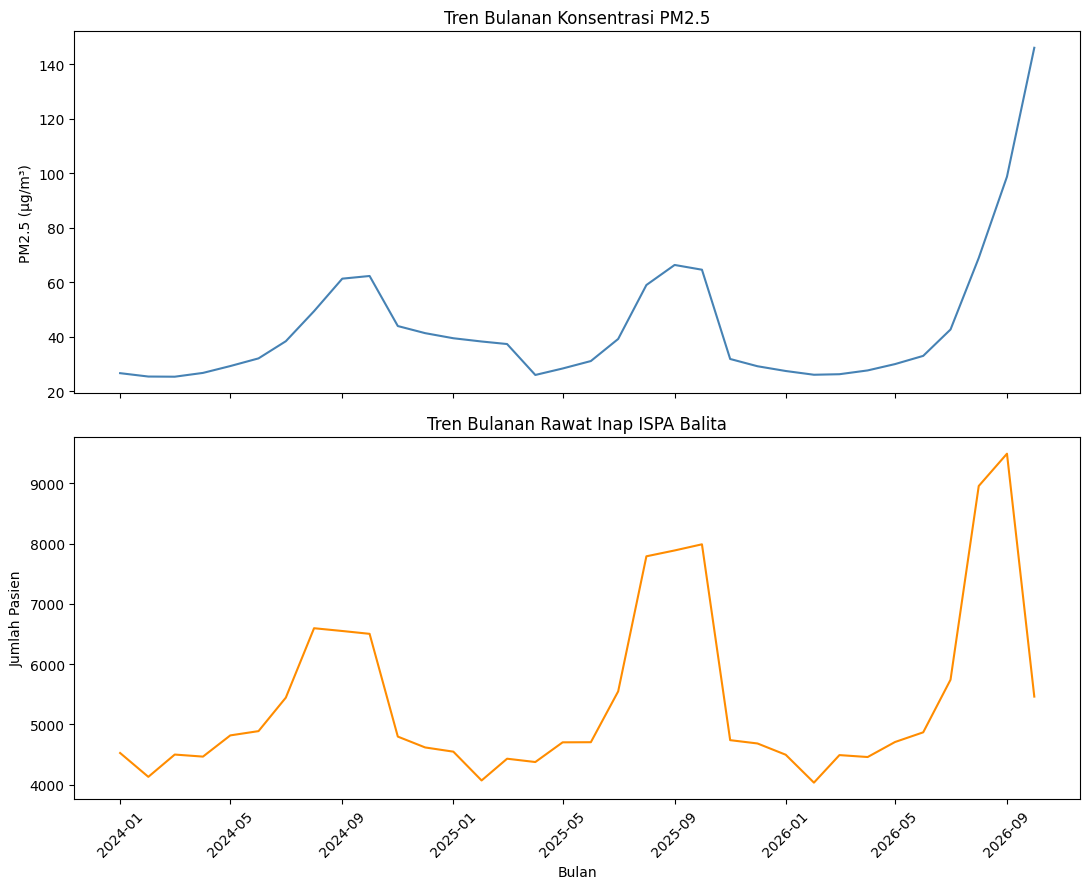

In [ ]:
# tren bulanan polusi dan kesehatan
aq_health_plot = aq_health[
    aq_health['date'] >= '2024-01-01'
].copy()

# tren bulanan PM2.5
aq_rep = aq_health_plot[
    aq_health_plot['is_representative'] == True
].copy()

pm_monthly = (
    aq_rep.set_index('date')
    .resample('MS')['pm25_mean']
    .mean()
    .reset_index()
)

# tren bulanan rawat inap ISPA balita
health_monthly = (
    aq_health_plot.set_index('date')
    .resample('MS')['resp_admissions_under5']
    .sum()
    .reset_index()
)

# grafik
fig, ax = plt.subplots(2, 1, figsize=(11, 9), sharex=True)

sns.lineplot(
    data=pm_monthly,
    x='date',
    y='pm25_mean',
    color='steelblue',
    ax=ax[0]
)

ax[0].set_title('Tren Bulanan Konsentrasi PM2.5')
ax[0].set_xlabel('')
ax[0].set_ylabel('PM2.5 (µg/m³)')

sns.lineplot(
    data=health_monthly,
    x='date',
    y='resp_admissions_under5',
    color='darkorange',
    ax=ax[1]
)

ax[1].set_title('Tren Bulanan Rawat Inap ISPA Balita')
ax[1].set_xlabel('Bulan')
ax[1].set_ylabel('Jumlah Pasien')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

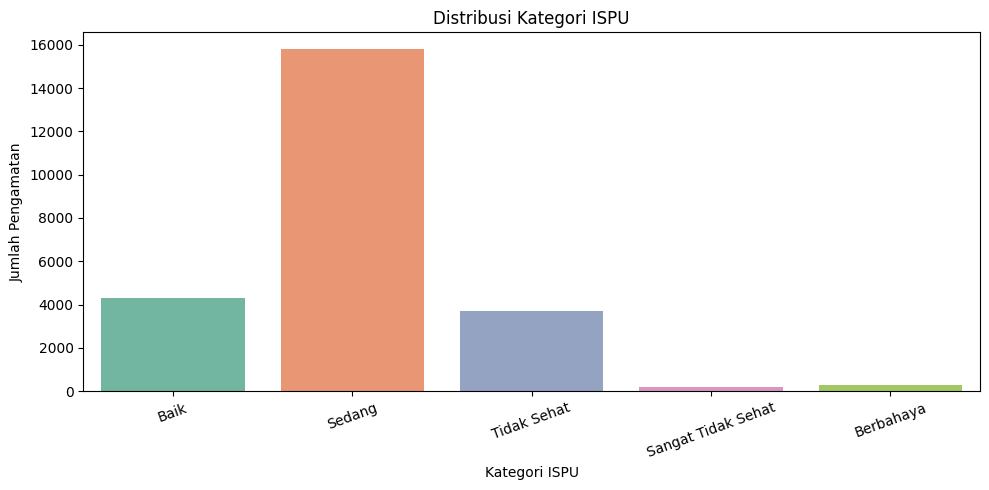

In [ ]:
# distribusi kategori ispu
ispu_dist = (
    aq_rep['kategori_ispu']
    .value_counts()
    .reindex([
        'Baik', 'Sedang', 'Tidak Sehat',
        'Sangat Tidak Sehat', 'Berbahaya'
    ], fill_value=0)
    .reset_index()
)

ispu_dist.columns = ['Kategori ISPU', 'Jumlah']

# grafik
plt.figure(figsize=(10, 5))

sns.barplot(
    data=ispu_dist,
    x='Kategori ISPU',
    y='Jumlah',
    hue='Kategori ISPU',
    palette='Set2',
    legend=False
)

plt.title('Distribusi Kategori ISPU')
plt.xlabel('Kategori ISPU')
plt.ylabel('Jumlah Pengamatan')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

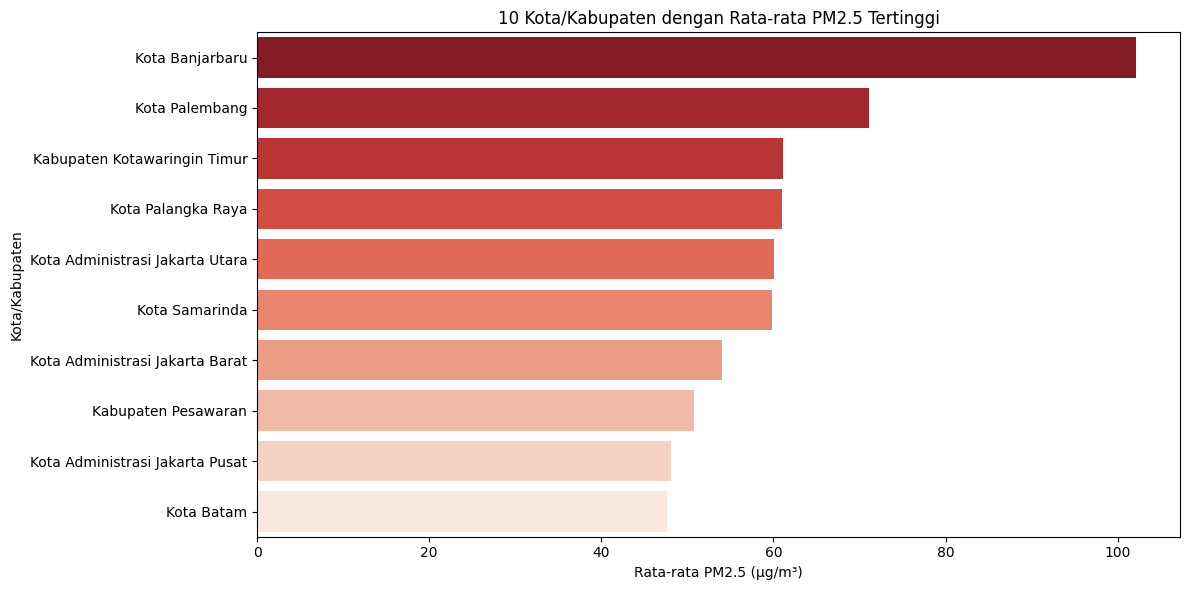

In [ ]:
# 10 kota/kabupaten
city = (
    aq_rep.groupby('kota_kabupaten')['pm25_mean']
    .mean()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

# grafik
plt.figure(figsize=(12, 6))

sns.barplot(
    data=city,
    x='pm25_mean',
    y='kota_kabupaten',
    hue='kota_kabupaten',
    palette='Reds_r',
    legend=False
)

plt.title('10 Kota/Kabupaten dengan Rata-rata PM2.5 Tertinggi')
plt.xlabel('Rata-rata PM2.5 (µg/m³)')
plt.ylabel('Kota/Kabupaten')
plt.tight_layout()
plt.show()

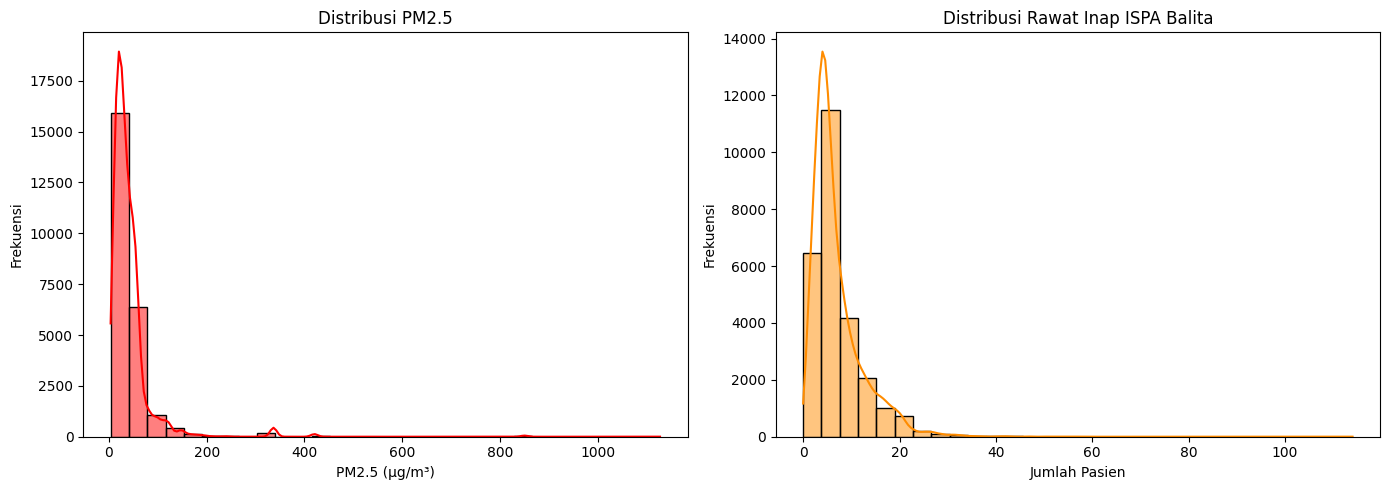

In [ ]:
# distribusi PM2.5 dan ISPA balita
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=aq_rep,
    x='pm25_mean',
    bins=30,
    kde=True,
    color='red',
    ax=ax[0]
)

ax[0].set_title('Distribusi PM2.5')
ax[0].set_xlabel('PM2.5 (µg/m³)')
ax[0].set_ylabel('Frekuensi')

sns.histplot(
    data=aq_health_plot,
    x='resp_admissions_under5',
    bins=30,
    kde=True,
    color='darkorange',
    ax=ax[1]
)

ax[1].set_title('Distribusi Rawat Inap ISPA Balita')
ax[1].set_xlabel('Jumlah Pasien')
ax[1].set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()

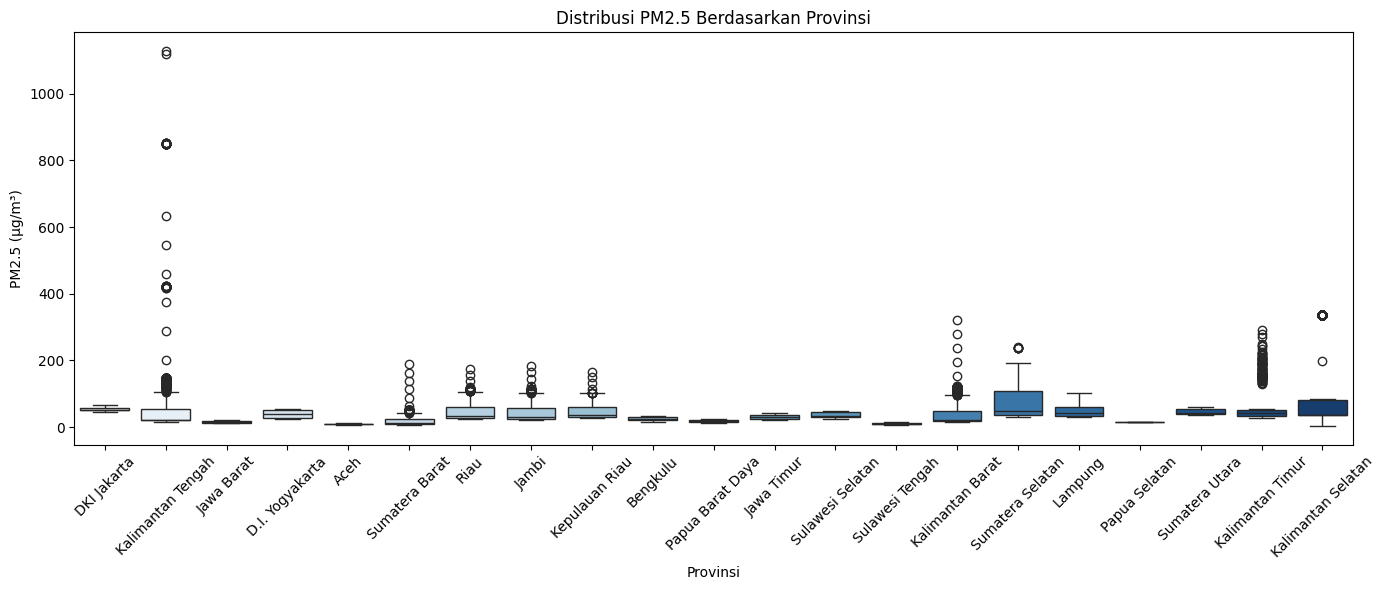

In [ ]:
# PM2.5 berdasarkan provinsi
plt.figure(figsize=(14, 6))

sns.boxplot(
    data=aq_rep,
    x='provinsi',
    y='pm25_mean',
    hue='provinsi',
    palette='Blues',
    legend=False
)

plt.title('Distribusi PM2.5 Berdasarkan Provinsi')
plt.xlabel('Provinsi')
plt.ylabel('PM2.5 (µg/m³)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

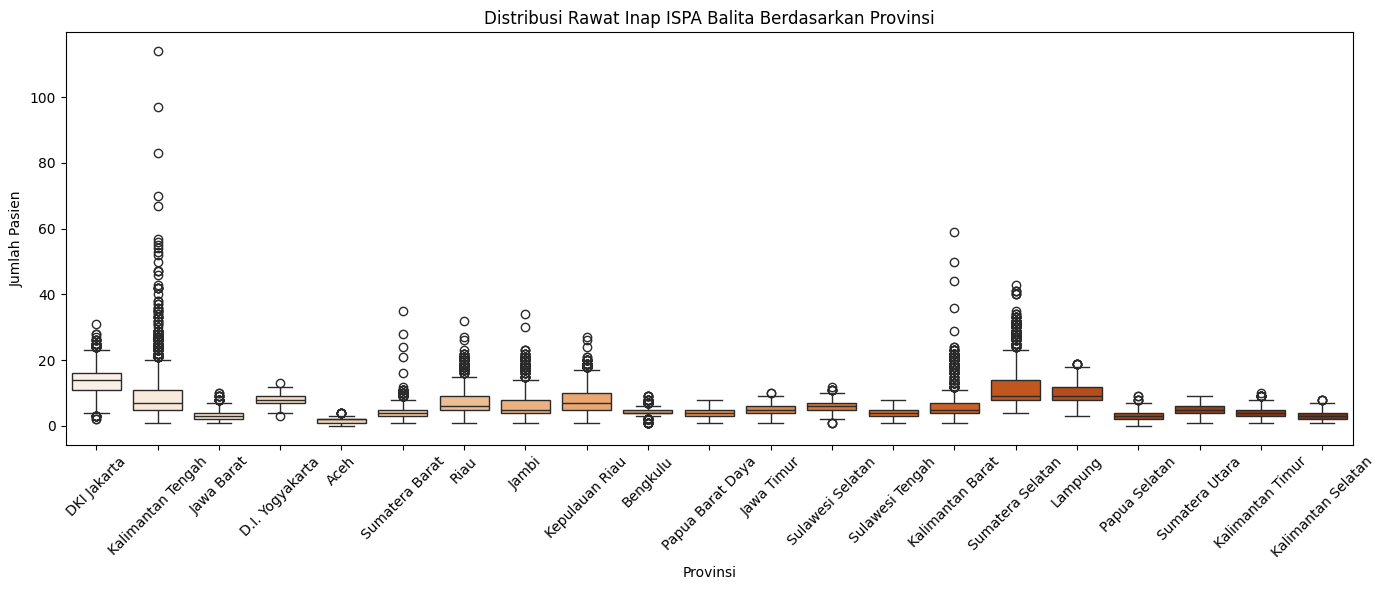

In [ ]:
# ISPA balita berdasarkan provinsi
health_dist = aq_health.drop_duplicates(
    subset=['hospital_id', 'date']
).copy()

plt.figure(figsize=(14, 6))

sns.boxplot(
    data=health_dist,
    x='provinsi',
    y='resp_admissions_under5',
    hue='provinsi',
    palette='Oranges',
    legend=False
)

plt.title('Distribusi Rawat Inap ISPA Balita Berdasarkan Provinsi')
plt.xlabel('Provinsi')
plt.ylabel('Jumlah Pasien')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

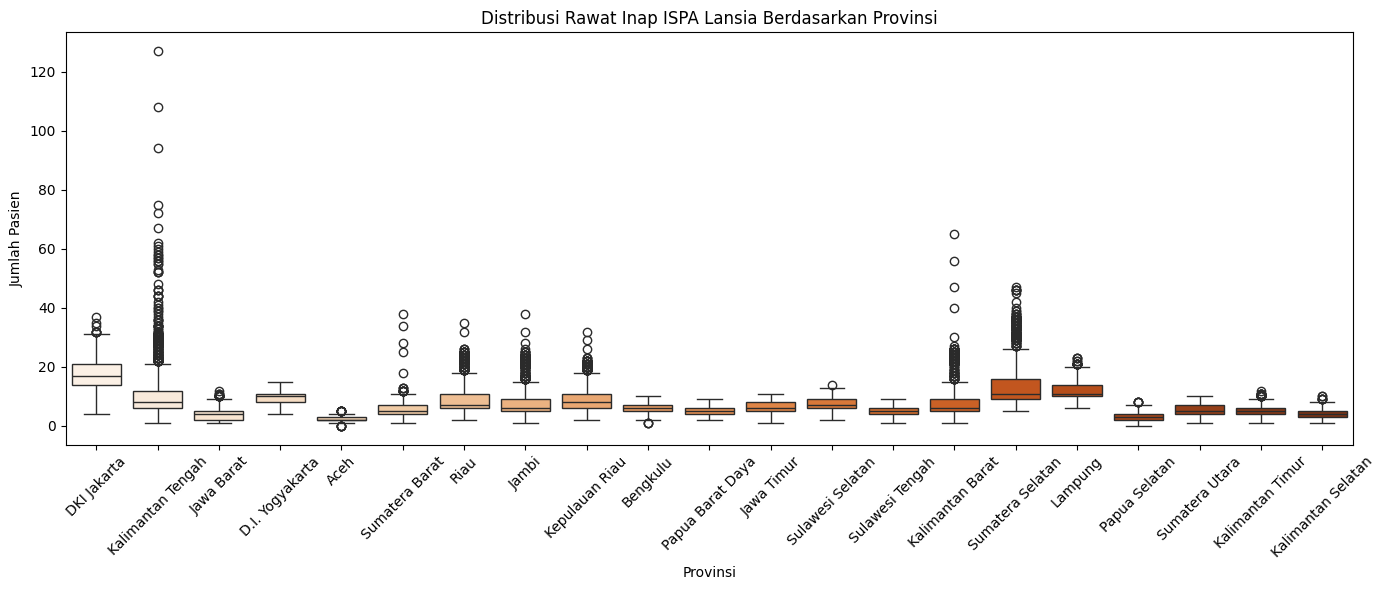

In [ ]:
# ISPA lansia berdasarkan provinsi
health_dist = aq_health.drop_duplicates(
    subset=['hospital_id', 'date']
).copy()

plt.figure(figsize=(14, 6))

sns.boxplot(
    data=health_dist,
    x='provinsi',
    y='resp_admissions_over60',
    hue='provinsi',
    palette='Oranges',
    legend=False
)

plt.title('Distribusi Rawat Inap ISPA Lansia Berdasarkan Provinsi')
plt.xlabel('Provinsi')
plt.ylabel('Jumlah Pasien')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

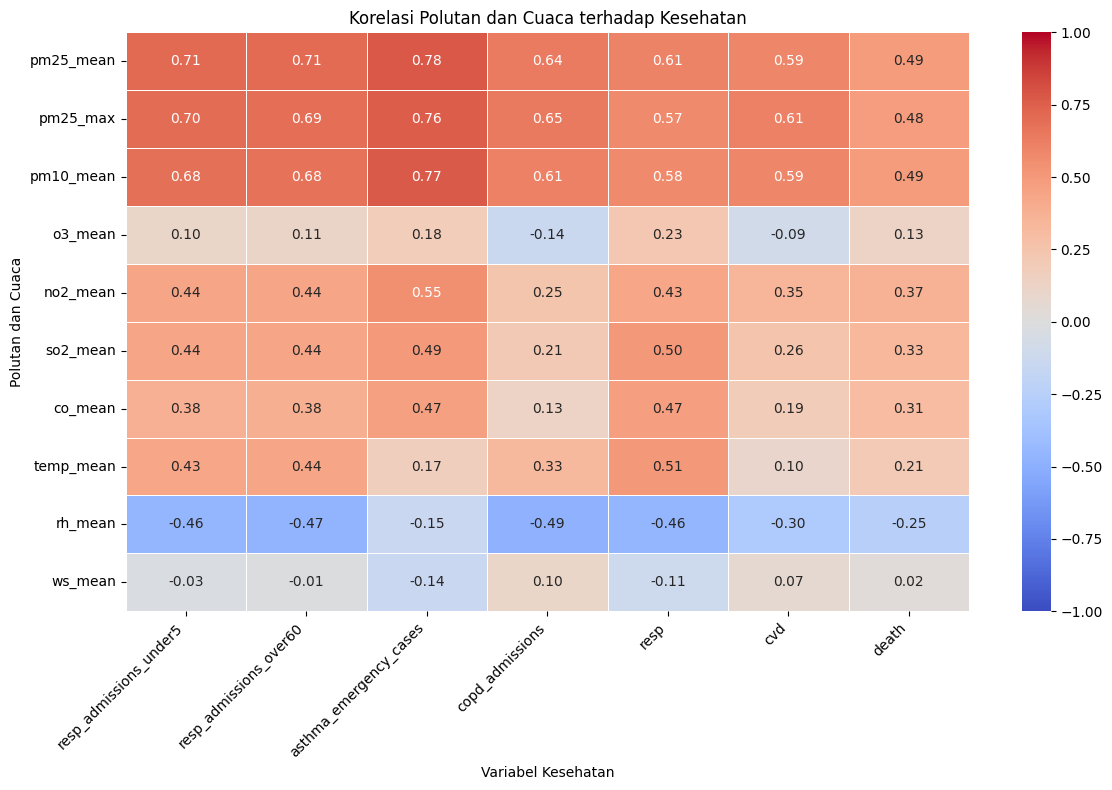

In [ ]:
# korelasi polutan dan cuaca terhadap kesehatan
x_cols = pollutant_cols + meteo_cols
y_cols = health_cols

corr_data = aq_rep[x_cols + y_cols].apply(
    pd.to_numeric,
    errors='coerce'
)

corr_matrix = corr_data.corr(method='spearman')
corr_health = corr_matrix.loc[x_cols, y_cols]

# grafik
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_health,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title('Korelasi Polutan dan Cuaca terhadap Kesehatan')
plt.xlabel('Variabel Kesehatan')
plt.ylabel('Polutan dan Cuaca')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

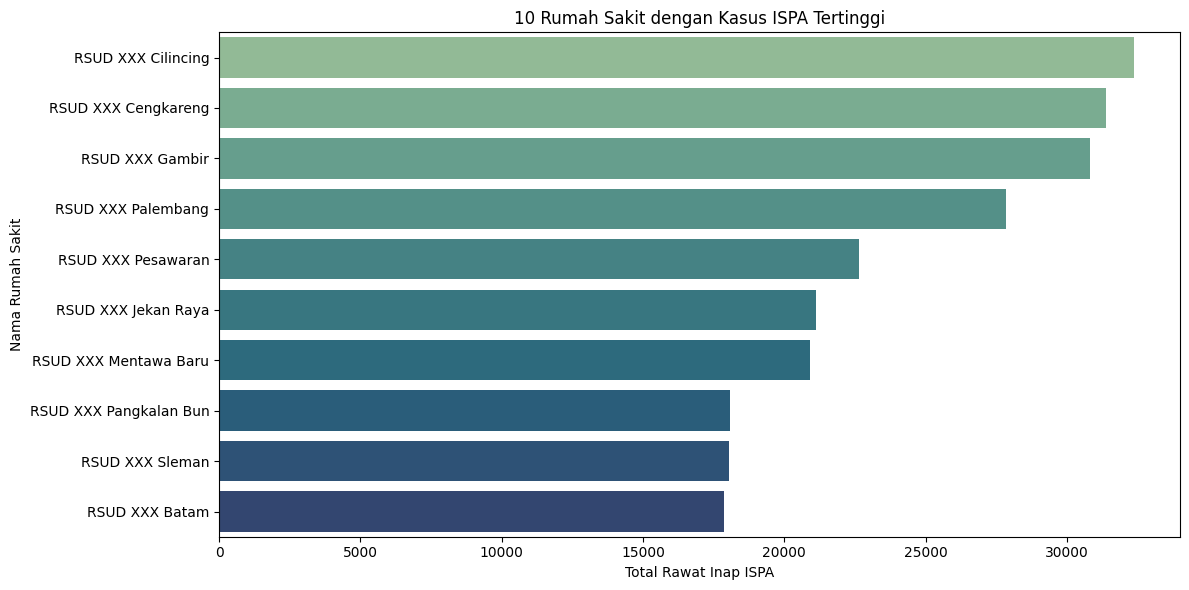

In [ ]:
# menghitung ISPA setiap rumah sakit
health_dist = aq_health_plot.drop_duplicates(
    subset=['hospital_id', 'date']
).copy()

health_dist['total_ispa'] = (
    health_dist['resp_admissions_under5'] +
    health_dist['resp_admissions_over60']
)

# 10 rumah sakit ISPA tertinggi
top_rs = (
    health_dist.groupby(
        ['hospital_id', 'nama_rumah_sakit']
    )['total_ispa']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

# grafik
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_rs,
    x='total_ispa',
    y='nama_rumah_sakit',
    hue='nama_rumah_sakit',
    palette='crest',
    legend=False
)

plt.title('10 Rumah Sakit dengan Kasus ISPA Tertinggi')
plt.xlabel('Total Rawat Inap ISPA')
plt.ylabel('Nama Rumah Sakit')
plt.tight_layout()
plt.show()

In [ ]:
# data kesehatan
health_day = aq_health_plot.drop_duplicates(
    subset=['hospital_id', 'date']
).copy()

health_day['date'] = pd.to_datetime(health_day['date'])

hari_order = [
    'Senin', 'Selasa', 'Rabu', 'Kamis',
    'Jumat', 'Sabtu', 'Minggu'
]

health_day['hari'] = health_day['date'].dt.dayofweek.map(
    dict(enumerate(hari_order))
)

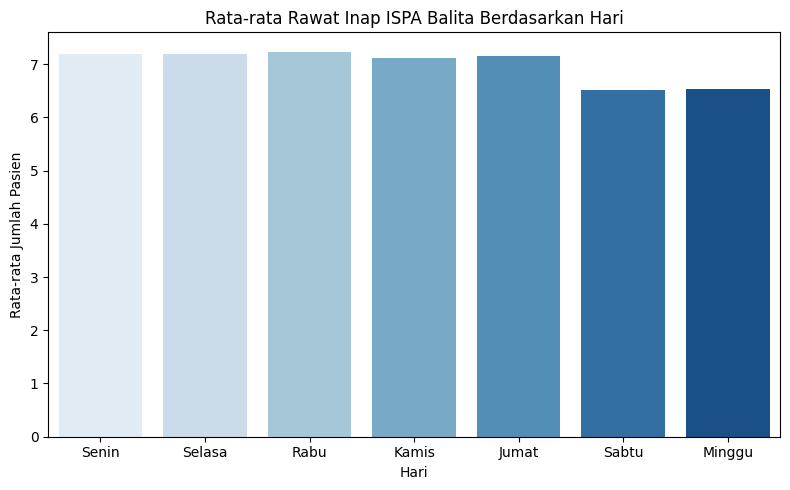

In [ ]:
# pola harian rawat inap ISPA balita
under5_daily = (
    health_day.groupby('hari')['resp_admissions_under5']
    .mean()
    .reindex(hari_order)
    .reset_index()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=under5_daily,
    x='hari',
    y='resp_admissions_under5',
    hue='hari',
    palette='Blues',
    legend=False
)

plt.title('Rata-rata Rawat Inap ISPA Balita Berdasarkan Hari')
plt.xlabel('Hari')
plt.ylabel('Rata-rata Jumlah Pasien')
plt.tight_layout()
plt.show()

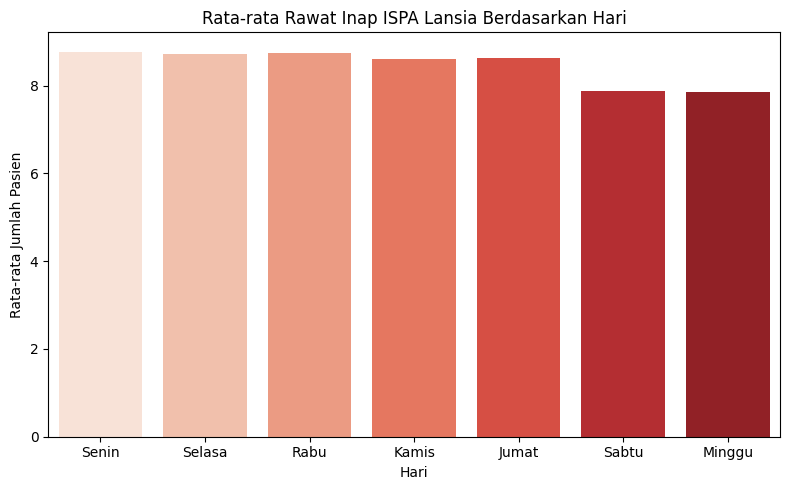

In [ ]:
# pola harian rawat inap ISPA lansia
over60_daily = (
    health_day.groupby('hari')['resp_admissions_over60']
    .mean()
    .reindex(hari_order)
    .reset_index()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=over60_daily,
    x='hari',
    y='resp_admissions_over60',
    hue='hari',
    palette='Reds',
    legend=False
)

plt.title('Rata-rata Rawat Inap ISPA Lansia Berdasarkan Hari')
plt.xlabel('Hari')
plt.ylabel('Rata-rata Jumlah Pasien')
plt.tight_layout()
plt.show()

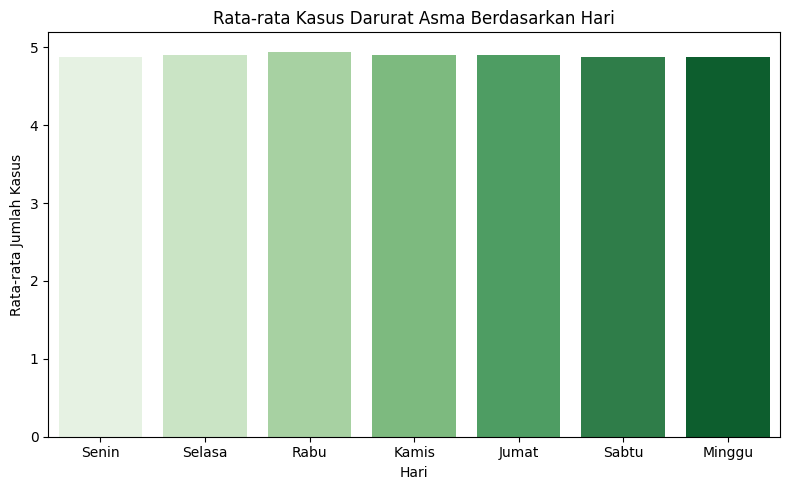

In [ ]:
# pola harian kasus darurat asma
asthma_daily = (
    health_day.groupby('hari')['asthma_emergency_cases']
    .mean()
    .reindex(hari_order)
    .reset_index()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=asthma_daily,
    x='hari',
    y='asthma_emergency_cases',
    hue='hari',
    palette='Greens',
    legend=False
)

plt.title('Rata-rata Kasus Darurat Asma Berdasarkan Hari')
plt.xlabel('Hari')
plt.ylabel('Rata-rata Jumlah Kasus')
plt.tight_layout()
plt.show()

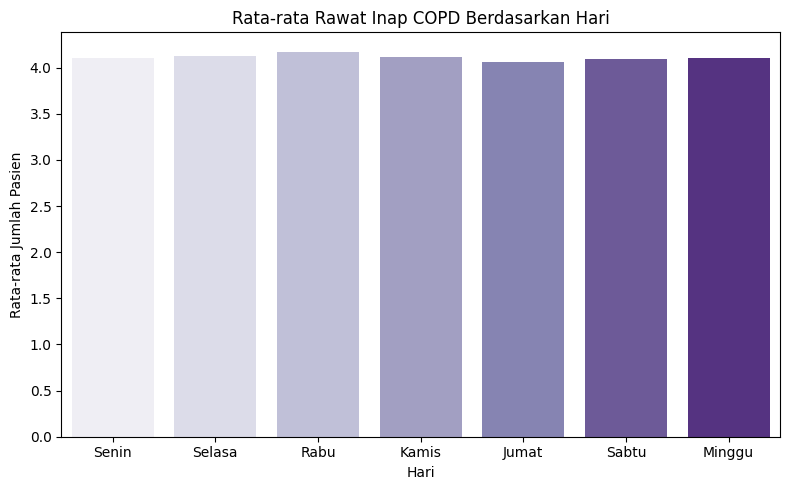

In [ ]:
# pola harian rawat inap COPD
copd_daily = (
    health_day.groupby('hari')['copd_admissions']
    .mean()
    .reindex(hari_order)
    .reset_index()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=copd_daily,
    x='hari',
    y='copd_admissions',
    hue='hari',
    palette='Purples',
    legend=False
)

plt.title('Rata-rata Rawat Inap COPD Berdasarkan Hari')
plt.xlabel('Hari')
plt.ylabel('Rata-rata Jumlah Pasien')
plt.tight_layout()
plt.show()

In [ ]:
# data PM2.5 dan kesehatan
scatter_data = aq_health_plot[
    ['pm25_mean', 'resp_admissions_under5', 'resp_admissions_over60']
].dropna().copy()

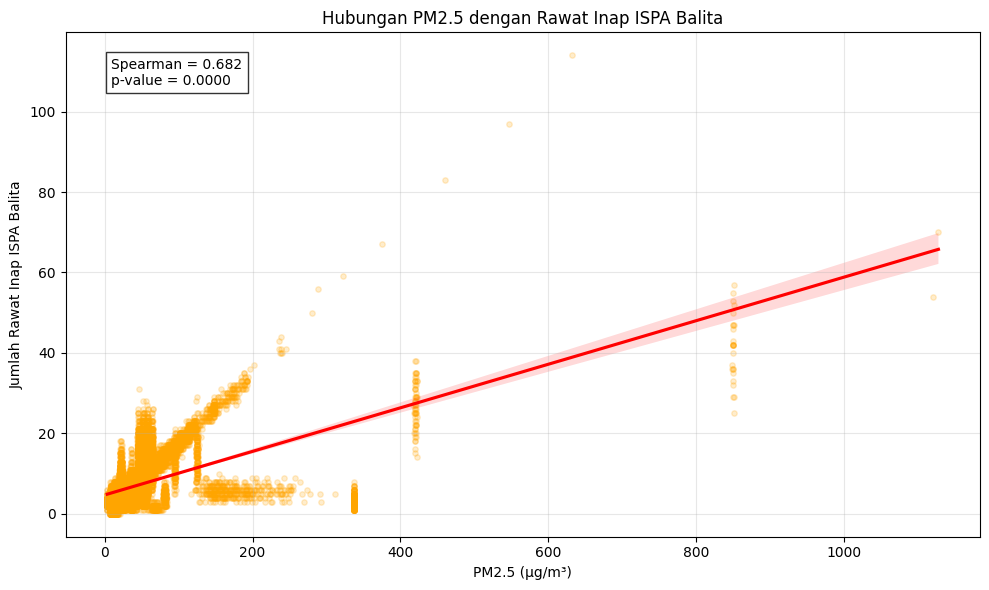

In [ ]:
# menghitung korelasi spearman
corr_under5, p_under5 = stats.spearmanr(
    scatter_data['pm25_mean'],
    scatter_data['resp_admissions_under5']
)

# membuat scatter plot
plt.figure(figsize=(10, 6))

sns.regplot(
    data=scatter_data,
    x='pm25_mean',
    y='resp_admissions_under5',
    scatter_kws={'alpha': 0.2, 'color': 'orange', 's': 15},
    line_kws={'color': 'red'}
)

plt.title('Hubungan PM2.5 dengan Rawat Inap ISPA Balita')
plt.xlabel('PM2.5 (µg/m³)')
plt.ylabel('Jumlah Rawat Inap ISPA Balita')

plt.text(
    0.05, 0.95,
    f'Spearman = {corr_under5:.3f}\np-value = {p_under5:.4f}',
    transform=plt.gca().transAxes,
    verticalalignment='top',
    bbox=dict(facecolor='white', alpha=0.8)
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

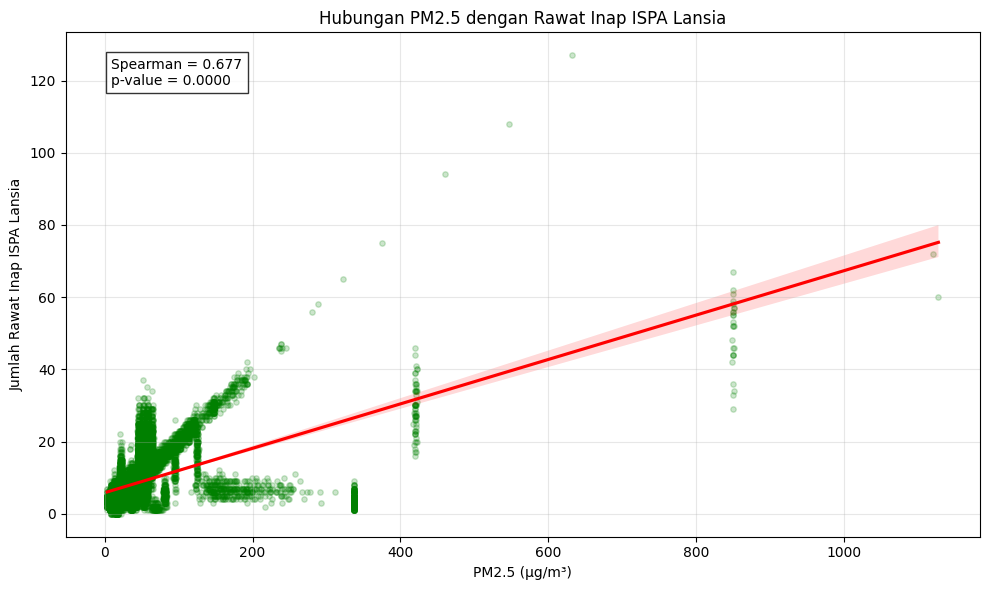

In [ ]:
# menghitung korelasi spearman
corr_over60, p_over60 = stats.spearmanr(
    scatter_data['pm25_mean'],
    scatter_data['resp_admissions_over60']
)

# membuat scatter plot
plt.figure(figsize=(10, 6))

sns.regplot(
    data=scatter_data,
    x='pm25_mean',
    y='resp_admissions_over60',
    scatter_kws={'alpha': 0.2, 'color': 'green', 's': 15},
    line_kws={'color': 'red'}
)

plt.title('Hubungan PM2.5 dengan Rawat Inap ISPA Lansia')
plt.xlabel('PM2.5 (µg/m³)')
plt.ylabel('Jumlah Rawat Inap ISPA Lansia')

plt.text(
    0.05, 0.95,
    f'Spearman = {corr_over60:.3f}\np-value = {p_over60:.4f}',
    transform=plt.gca().transAxes,
    verticalalignment='top',
    bbox=dict(facecolor='white', alpha=0.8)
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()